# FMPI analysis of ABR

### Necessary imports

In [2]:

import math
import matplotlib.pyplot as plt
%matplotlib widget
import numpy as np
import scipy
from scipy import signal
import wfdb
import os
import glob
import re
import pandas as pd
import collections
from matplotlib.colors import Normalize, ListedColormap
from matplotlib.cm import ScalarMappable

### Load data

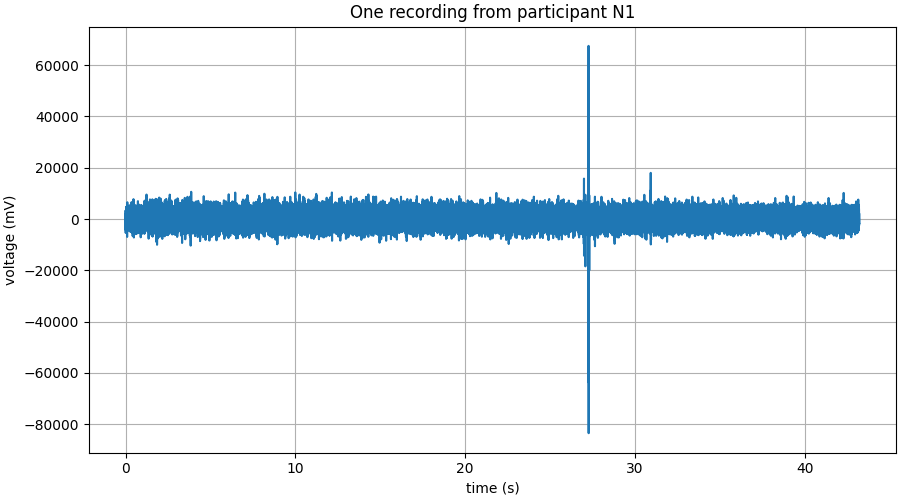

[[ 0.00000000e+00  2.08333333e-05  4.16666667e-05 ...  4.21279375e+01
   4.21279583e+01  4.21279792e+01]
 [-8.20553306e+03 -7.98532966e+03 -7.77642730e+03 ...  2.30431558e+03
   1.91884042e+03  1.53965951e+03]]


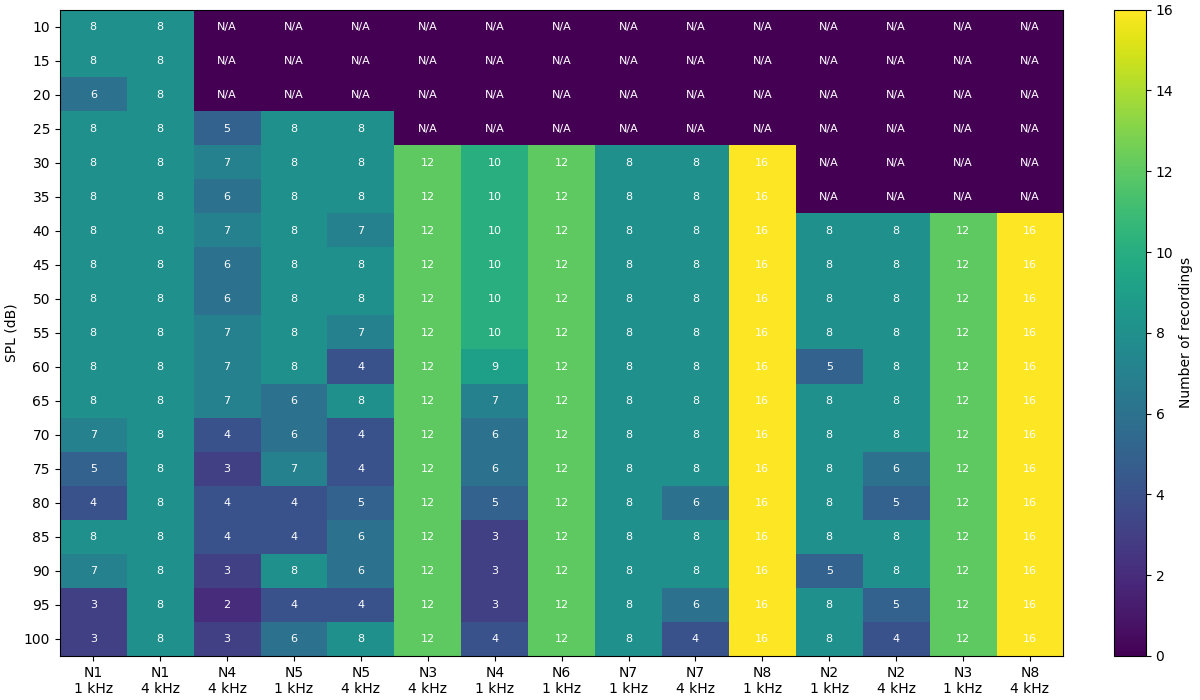

In [3]:

##Load the first piece of data
#Do initial plotting

r = wfdb.rdrecord('Physio-ABR-Data/raw/N1/N1_evoked_raw_100_F1_R1')
amp = r.p_signal[:,0]
t = np.arange(len(amp)) / r.fs
plt.figure(figsize=(9, 5), constrained_layout=True)
plt.plot(t, amp)
plt.grid(True)
plt.xlabel('time (s)')
plt.ylabel('voltage (mV)')
plt.title('One recording from participant N1')
plt.show()

### Visualiser



rows = []
for f in glob.glob('Physio-ABR-Data/raw/*/*.hea'):
    m = re.search(r'<SPL>: (\d+) <Stim Freq \(kHz\)>: (\d)', open(f).read())
    rows.append((f.replace('\\', '/').split('/')[-2], int(m[1]), int(m[2])))

df = pd.DataFrame(rows, columns=['subject', 'spl', 'freq'])
counts = df.groupby(['spl', 'subject', 'freq']).size().unstack(['subject', 'freq'])
counts = counts.reindex(range(10, 101, 5)).fillna(0).astype(int)

M = counts.values
plt.figure(figsize=(12, 7), constrained_layout=True)
plt.imshow(M, cmap='viridis', aspect='auto')
plt.colorbar(label='Number of recordings')
plt.xticks(range(M.shape[1]), [f'{s}\n{k} kHz' for s, k in counts.columns])
plt.yticks(range(M.shape[0]), counts.index)
plt.ylabel('SPL (dB)')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        plt.text(j, i, M[i, j] if M[i, j] else 'N/A', ha='center', va='center', color='w', fontsize=8)
        
        
### Grouping the data

class Recs(list):
    """List of record paths that returns a (2, n_samples) array when indexed."""
    def __getitem__(self, i):
        r = wfdb.rdrecord(super().__getitem__(i))
        amp = r.p_signal[:, 0]                              # nV
        return np.array([np.arange(len(amp)) / r.fs, amp])  # row 0 = time (s), row 1 = amplitude
    def __iter__(self):
        return (self[i] for i in range(len(self)))


groups = collections.defaultdict(Recs)
for f in sorted(glob.glob('Physio-ABR-Data/raw/*/*.hea')):
    name = f.replace('\\', '/').split('/')[-1]
    subj, spl, freq, rep, x = re.match(r'(N\d+)_evoked_raw_(\d+)_F(\d)_R(\d+)(_x)?\.hea', name).groups()
    groups[(subj, int(spl), int(freq))].append(f[:-4])


print(groups[('N3', int(40), int(4))][2])


### Cleaning data

In [37]:
import os
import numpy as np
from scipy import signal

# Step 1: downsample to 8 kHz
def downsample(amp, fs, fs_new=8000):
    q = int(fs // fs_new)                          # 48000 / 8000 = 6
    return signal.decimate(amp, q, ftype='fir', zero_phase=True), fs_new

# Step 2: Kaiser linear-phase bandpass 68-1350 Hz (65 dB stop-band, 1 Hz transition)
def bandpass(x, fs, lo=68, hi=1350, atten=65, width=1.0):
    numtaps, beta = signal.kaiserord(atten, width / (fs / 2))
    numtaps += (numtaps % 2 == 0)                  # odd length
    h = signal.firwin(numtaps, [lo, hi], pass_zero=False, window=('kaiser', beta), fs=fs)
    return signal.fftconvolve(x, h, mode='same')   # linear phase, delay compensated

# Step 3: cut into 20 ms sweeps, one per trial (2002 samples at the original 48 kHz)
def sweep(x, fs, fs_orig=48000, trial=2002, dur=0.020):
    n_trials = int(len(x) * fs_orig / fs // trial)
    starts = np.round(np.arange(n_trials, dtype=float) * trial * fs / fs_orig).astype(int)
    L = int(round(dur * fs))
    starts = starts[starts + L <= len(x)]
    return np.stack([x[s:s + L] for s in starts]), np.arange(L) / fs * 1000   # (n_sweeps, L), time in ms

# Application + saving (one file per sample/recording)
out_dir = "clean_samples"
os.makedirs(out_dir, exist_ok=True)

THRESH = 1e6                                       # raw amplitude limit
skipped = []

clean_d = {}
for key in groups:                                 # key = (subj, spl, freq)
    subj, spl, freq = key
    sweeps = []
    for r, (t, amp) in enumerate(groups[key], start=1):
        if not np.isfinite(amp).all() or np.abs(amp).max() > THRESH:
            skipped.append(f"{subj}_{spl}dB_F{freq}_R{r}")
            continue
        x, fs = downsample(amp, 48000)
        y = bandpass(x, fs)
        sw, t_ms = sweep(y, fs)
        sw = sw.astype(np.float32)
        np.save(os.path.join(out_dir, f"{subj}_{spl}dB_F{freq}_R{r}.npy"), sw)
        sweeps.append(sw)
    if sweeps:
        clean_d[key] = np.concatenate(sweeps)

np.save(os.path.join(out_dir, "t_ms.npy"), t_ms)
print(len(skipped), skipped)


76 ['N1_100dB_F4_R3', 'N1_100dB_F4_R7', 'N1_10dB_F4_R5', 'N1_15dB_F1_R3', 'N1_15dB_F1_R4', 'N1_15dB_F4_R1', 'N1_20dB_F1_R1', 'N1_20dB_F1_R4', 'N1_20dB_F1_R5', 'N1_20dB_F1_R6', 'N1_20dB_F4_R5', 'N1_25dB_F4_R5', 'N1_30dB_F1_R2', 'N1_30dB_F4_R2', 'N1_30dB_F4_R5', 'N1_35dB_F1_R2', 'N1_35dB_F4_R1', 'N1_40dB_F4_R5', 'N1_45dB_F1_R2', 'N1_45dB_F1_R6', 'N1_45dB_F4_R1', 'N1_45dB_F4_R5', 'N1_50dB_F1_R2', 'N1_50dB_F1_R6', 'N1_50dB_F4_R5', 'N1_55dB_F1_R6', 'N1_55dB_F4_R1', 'N1_55dB_F4_R5', 'N1_55dB_F4_R7', 'N1_60dB_F4_R3', 'N1_65dB_F1_R6', 'N1_65dB_F4_R2', 'N1_65dB_F4_R3', 'N1_65dB_F4_R7', 'N1_70dB_F1_R2', 'N1_70dB_F1_R6', 'N1_70dB_F4_R3', 'N1_75dB_F1_R3', 'N1_75dB_F4_R3', 'N1_75dB_F4_R7', 'N1_80dB_F1_R2', 'N1_80dB_F4_R3', 'N1_85dB_F1_R2', 'N1_85dB_F4_R3', 'N1_85dB_F4_R7', 'N1_90dB_F4_R3', 'N1_90dB_F4_R7', 'N1_95dB_F1_R3', 'N1_95dB_F4_R7', 'N4_50dB_F1_R2', 'N5_100dB_F1_R3', 'N5_100dB_F1_R5', 'N5_25dB_F1_R5', 'N5_25dB_F4_R5', 'N5_25dB_F4_R8', 'N5_30dB_F1_R1', 'N5_35dB_F1_R1', 'N5_35dB_F1_R5', 'N5_35

### Visualise if changed

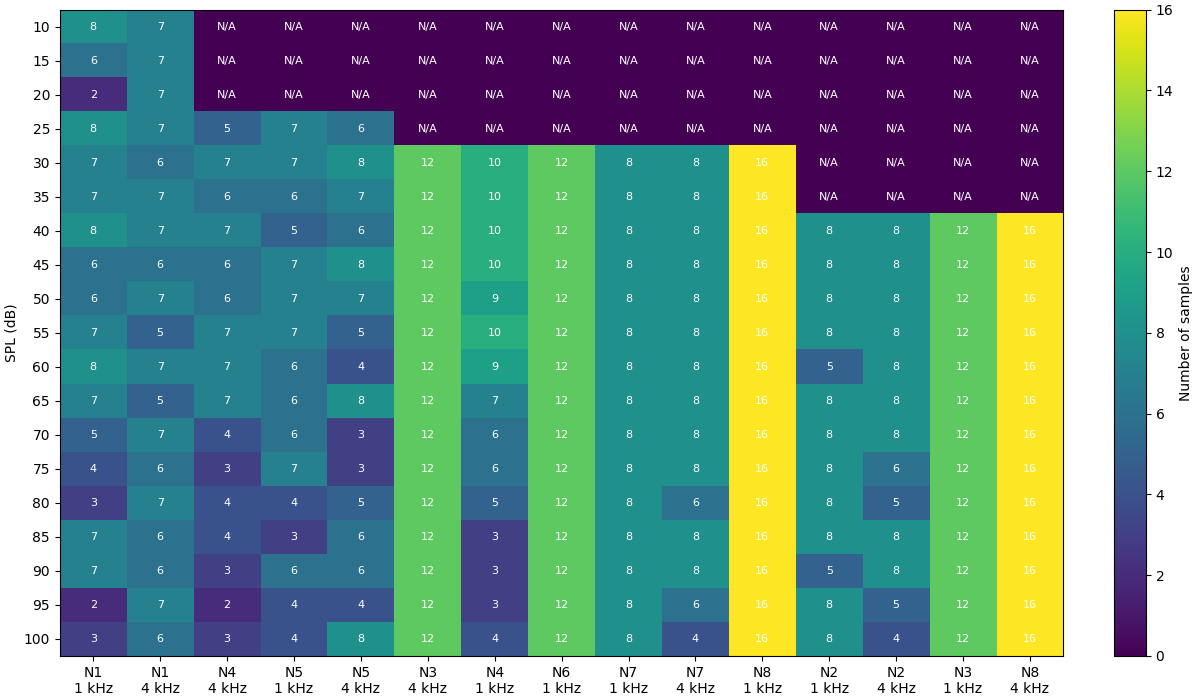

In [ ]:
rows = []
for f in glob.glob('clean_samples/means_over_sweep/N*.npy'):
    subj, spl, freq = re.match(r'(N\d+)_(\d+)dB_F(\d)', os.path.basename(f)).groups()
    rows.append((subj, int(spl), int(freq)))

df = pd.DataFrame(rows, columns=['subject', 'spl', 'freq'])
counts = df.groupby(['spl', 'subject', 'freq']).size().unstack(['subject', 'freq'])
counts = counts.reindex(range(10, 101, 5)).fillna(0).astype(int)

M = counts.values
plt.figure(figsize=(12, 7), constrained_layout=True)
plt.imshow(M, cmap='viridis', aspect='auto')
plt.colorbar(label='Number of samples')
plt.xticks(range(M.shape[1]), [f'{s}\n{k} kHz' for s, k in counts.columns])
plt.yticks(range(M.shape[0]), counts.index)
plt.ylabel('SPL (dB)')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        plt.text(j, i, M[i, j] if M[i, j] else 'N/A', ha='center', va='center', color='w', fontsize=8)
plt.show()


### 1. Mean over sweeps

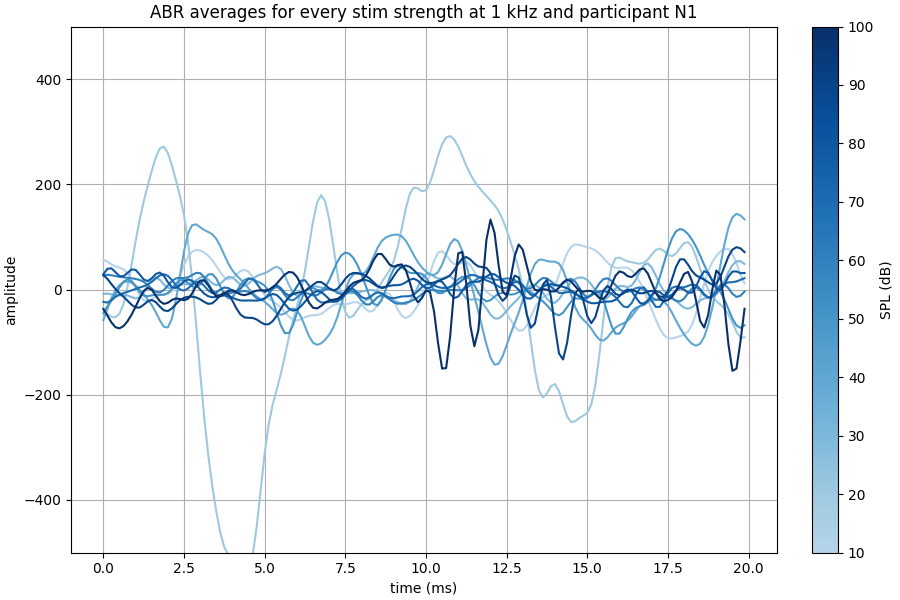

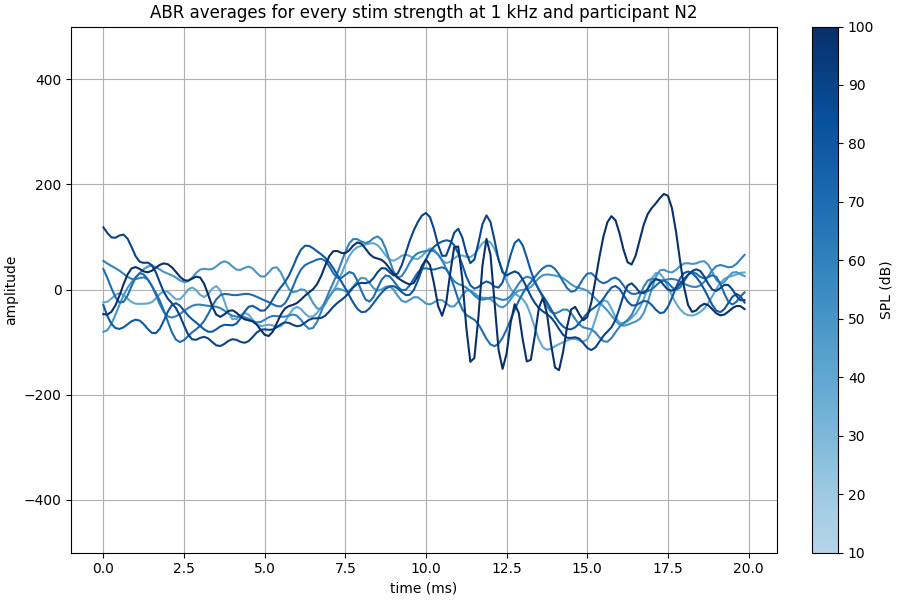

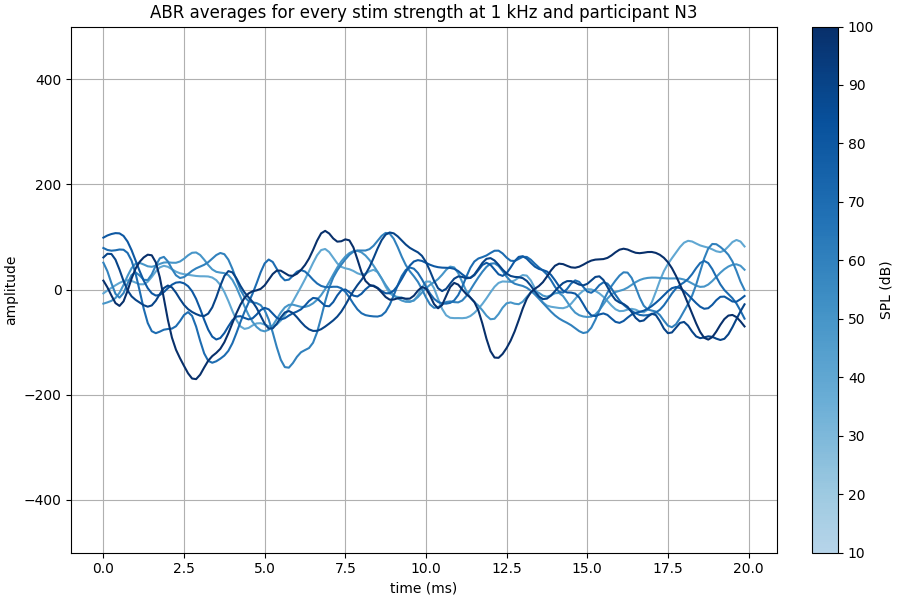

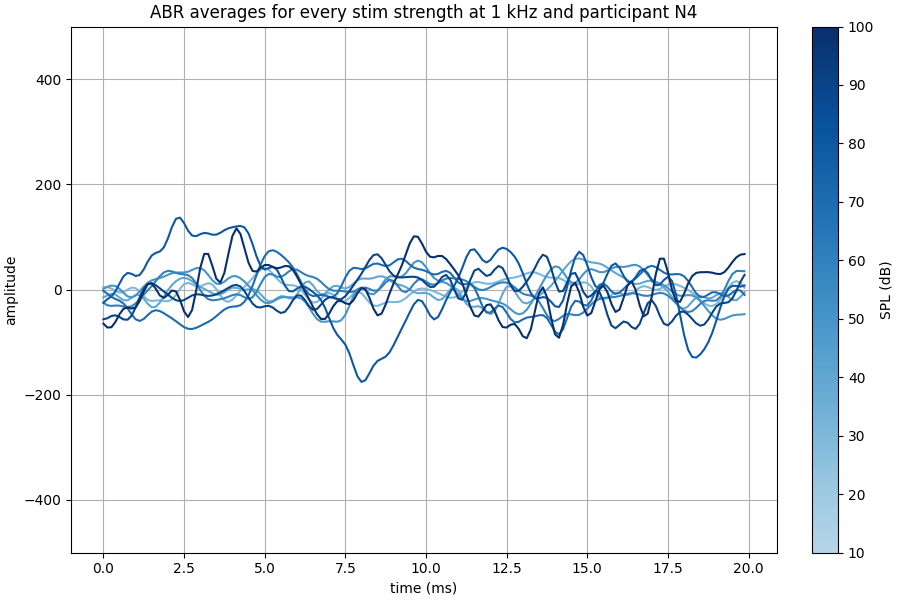

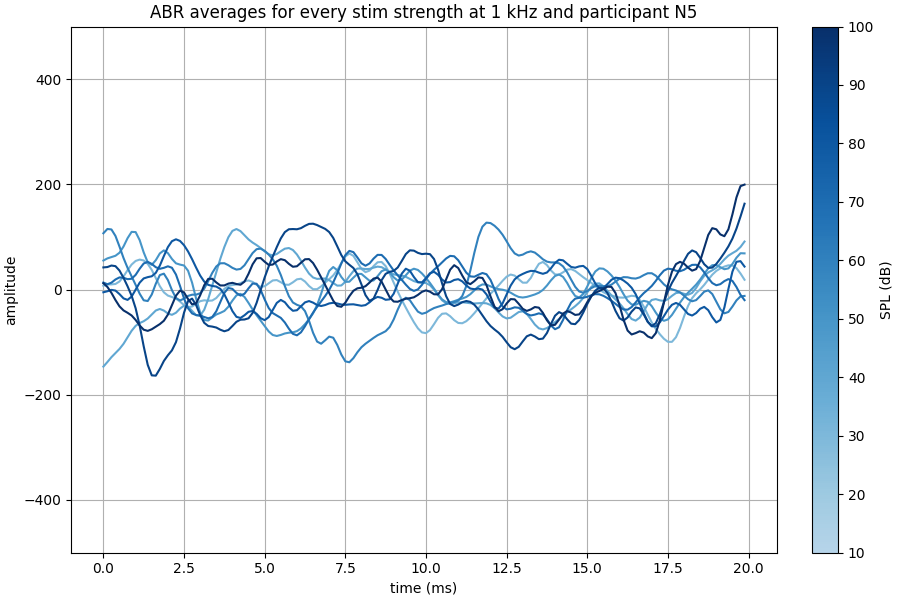

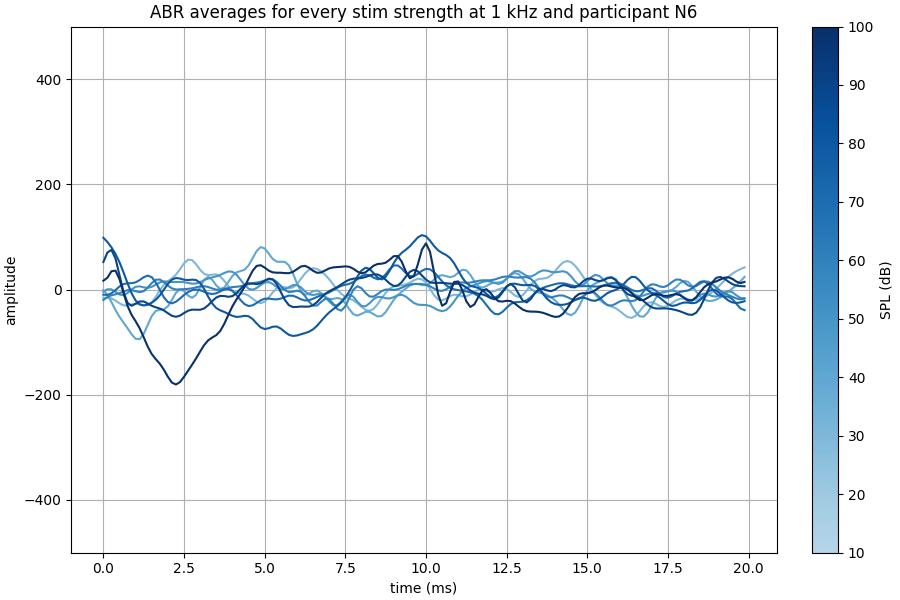

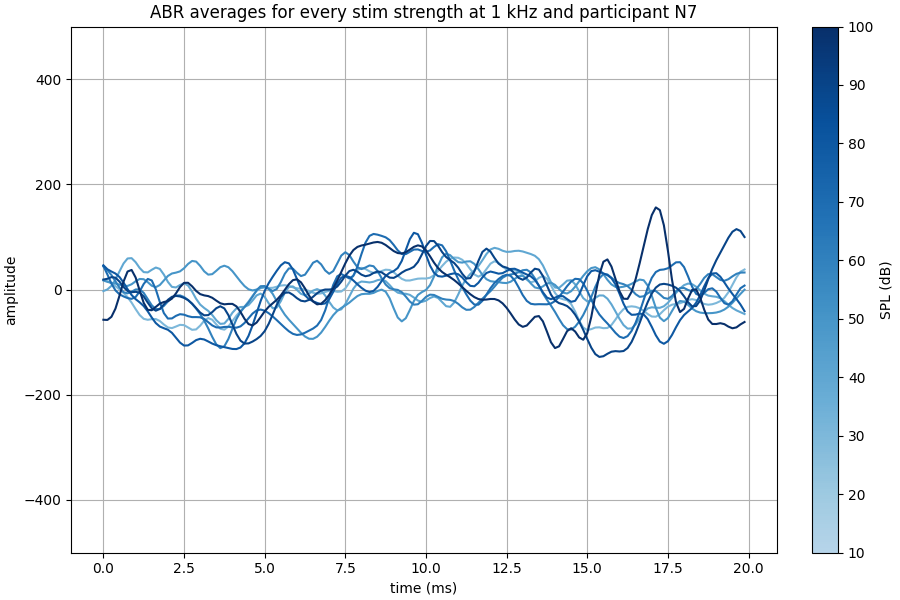

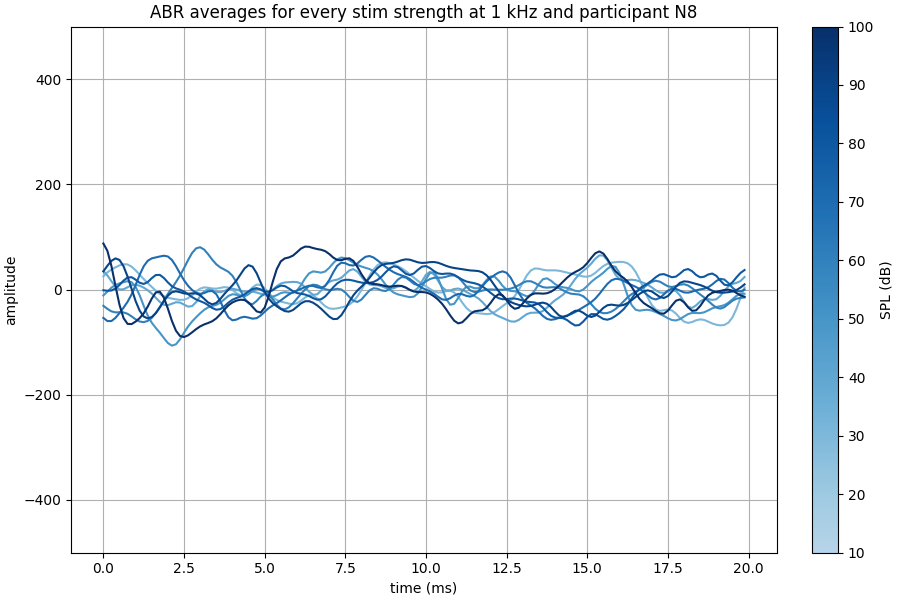

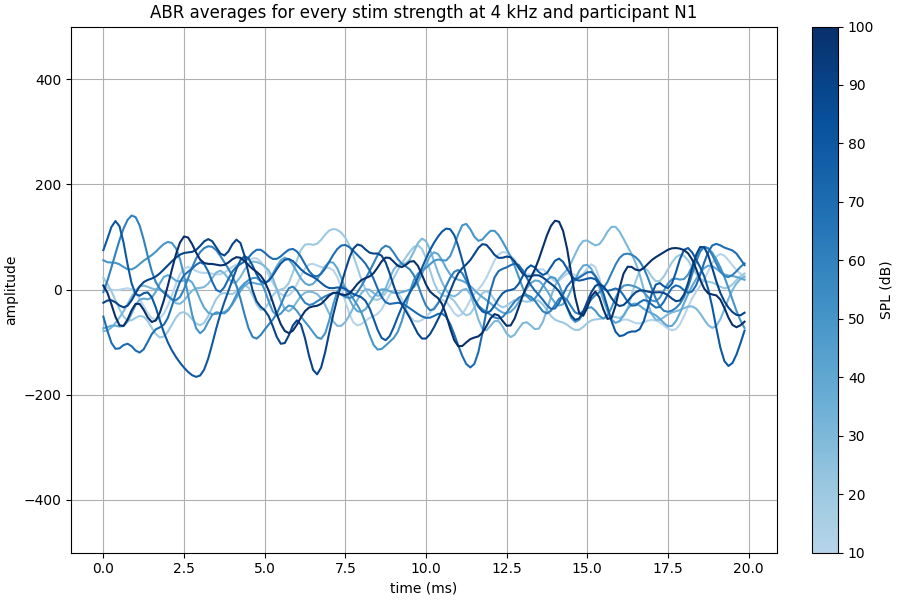

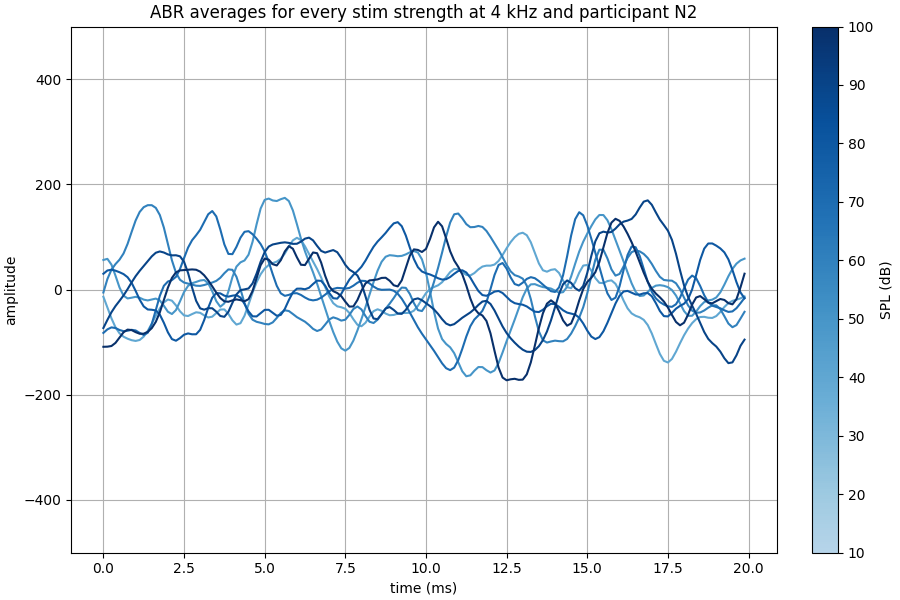

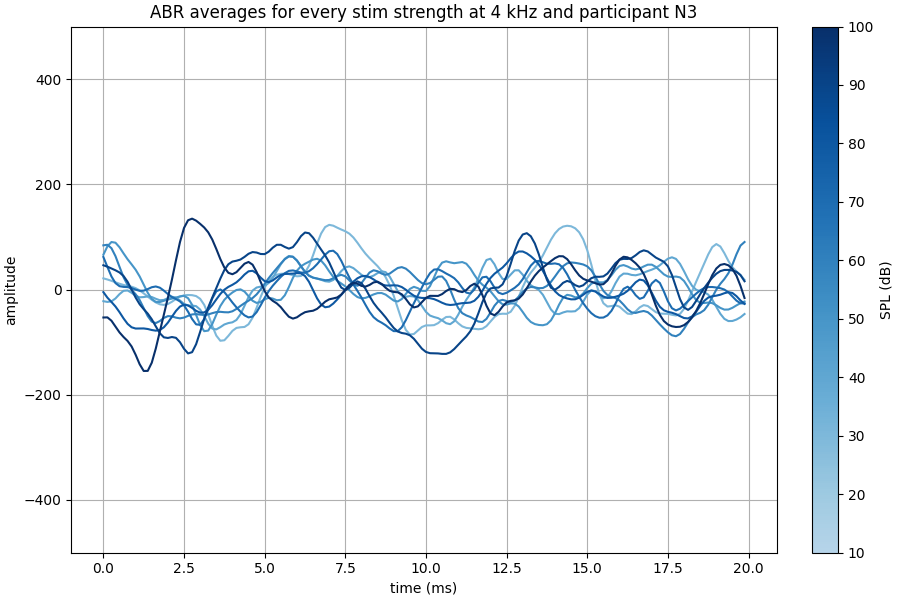

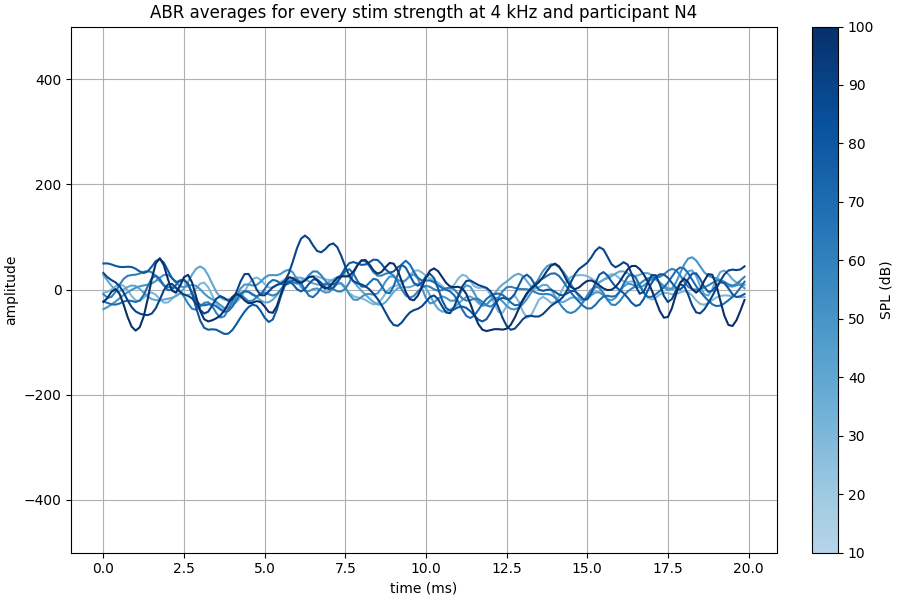

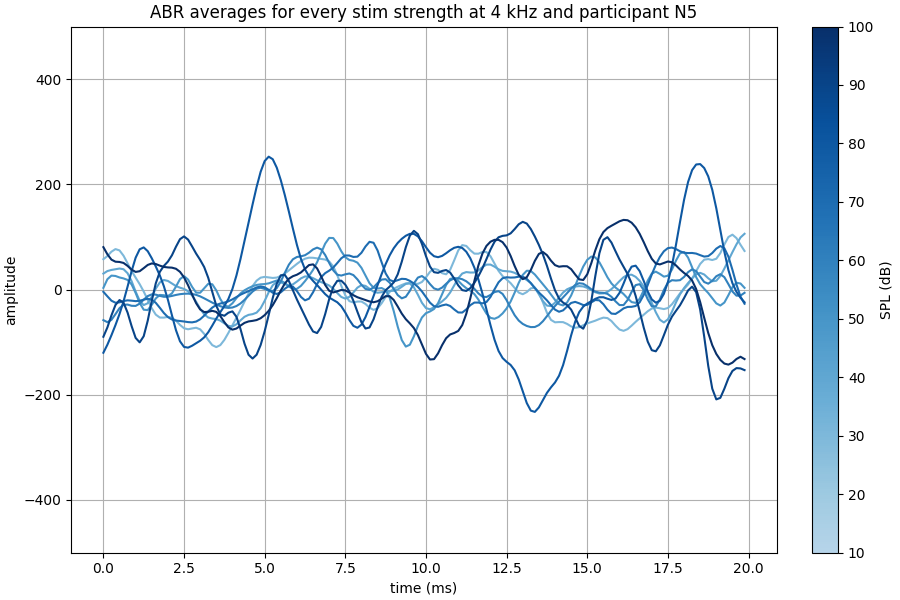

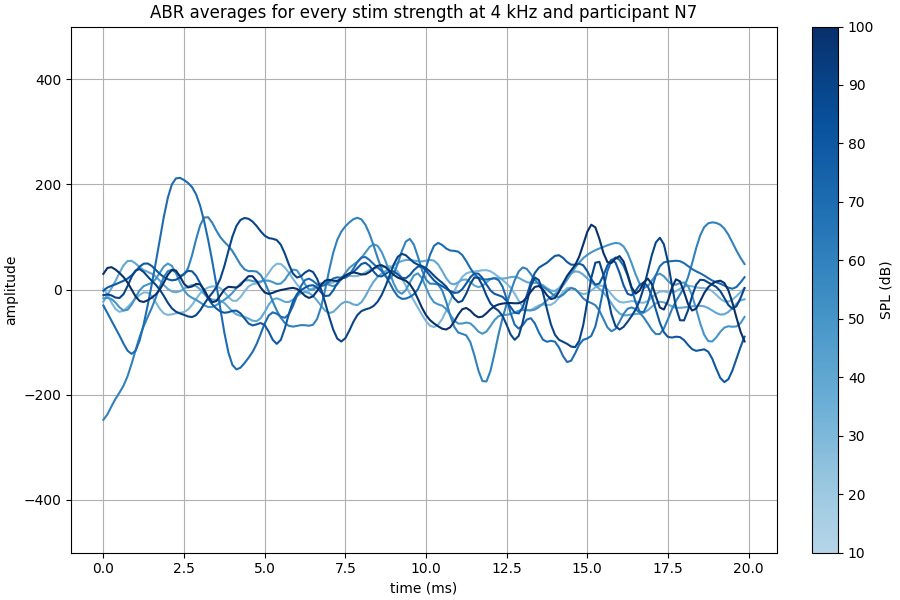

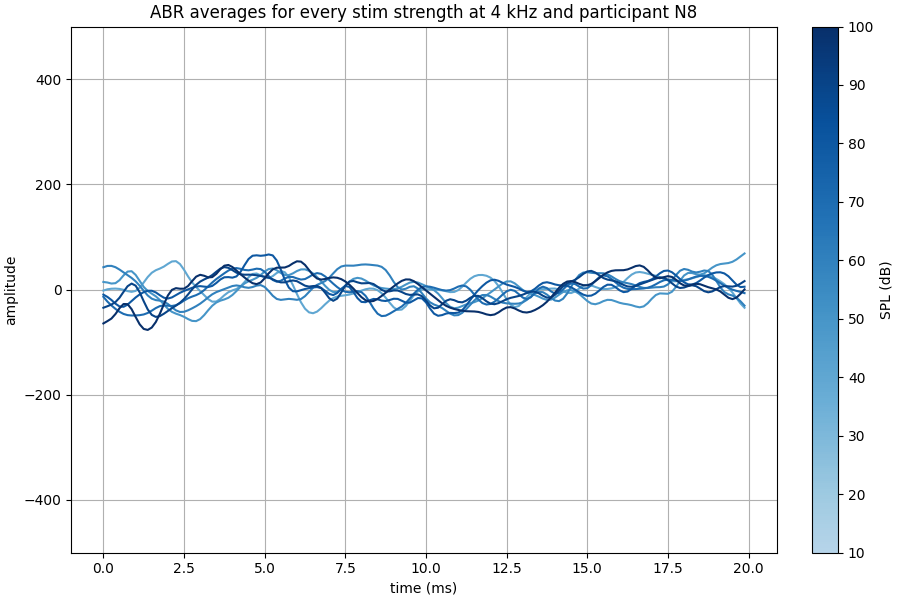

In [26]:
t_ms = np.load('clean_samples/means_over_sweep/t_ms.npy')

def mean_sweep(pattern):
    """Mean over every sweep in all files matching pattern, one value per time step."""
    total = np.zeros(len(t_ms))
    count = 0
    for f in sorted(glob.glob(pattern)):
        a = np.load(f)                                  # (n_sweeps, len(t_ms))
        total += a.sum(axis=0, dtype=np.float64)
        count += a.shape[0]
    return total / count if count else None




stim_strengths = [int(a) for a in np.linspace(10, 100, 10)]
cmap = ListedColormap(plt.cm.Blues(np.linspace(0.3, 1, 256)))      # light blue -> dark blue
norm = Normalize(vmin=min(stim_strengths), vmax=max(stim_strengths))
freq_list = [1,4]

for f in freq_list:
    for i in range(1,9):
        if f == 4 and i == 6:
            continue
        fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
        for dB in stim_strengths:
            y_hat = mean_sweep(f'clean_samples/means_over_sweep/N{i}_{dB}dB_F{f}_*.npy')
            if y_hat is not None:
                ax.plot(t_ms, y_hat, color=cmap(norm(dB)))
        ax.set_title(f'ABR averages for every stim strength at {f} kHz and participant N{i}')
        
        
        ax.set_ylim(-500, 500)
        ax.set_xlabel('time (ms)')
        ax.set_ylabel('amplitude')
        ax.grid(True)
        fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, label='SPL (dB)')   # bar on the right
        plt.show()
        



### Within group variance

In [ ]:
'''
##Create noise directory
src_dir = 'clean_samples/means_over_sweep'
out_dir = 'clean_samples/clean_noise_data'
os.makedirs(out_dir, exist_ok=True)

# group the files by (subject, spl, freq)
files = collections.defaultdict(list)
for f in sorted(glob.glob(f'{src_dir}/N*_R*.npy')):
    subj, spl, freq = re.match(r'(N\d+)_(\d+)dB_F(\d)_R', os.path.basename(f)).groups()
    files[(subj, int(spl), int(freq))].append(f)

# subtract the group mean sweep from every sweep, one file per original file (same name)
for key, fl in files.items():
    arrs = [np.load(f) for f in fl]                              # each (n_sweeps, len(t_ms))
    mean = np.concatenate(arrs).mean(axis=0, dtype=np.float64)   # mean over all sweeps of the group
    for f, a in zip(fl, arrs):
        np.save(os.path.join(out_dir, os.path.basename(f)), (a - mean).astype(np.float32))
'''

## Create variance
## directory
noise_dir = 'clean_samples/clean_noise_data'
var_dir = 'clean_samples/within_group_variance'
os.makedirs(var_dir, exist_ok=True)


for f in sorted(glob.glob(f'{noise_dir}/N*_R*.npy')):
    a = np.load(f).astype(np.float64)                          # (n_sweeps, P)
    dev = a - a.mean(axis=1, keepdims=True)                    # remove each sweep's own time mean
    var = (dev**2).sum(axis=1) / (a.shape[1] - 1)              # sum over time steps / (P-1), one value per sweep
    np.save(os.path.join(var_dir, os.path.basename(f)), var)   # shape (n_sweeps,)

### Weight Vector

In [29]:

###Create directory

var_dir = 'clean_samples/within_group_variance'
w_dir = 'clean_samples/weights'
os.makedirs(w_dir, exist_ok=True)

###organise into groups
groups_v = collections.defaultdict(list)
for f in sorted(glob.glob(f'{var_dir}/N*_R*.npy')):
    subj, spl, freq = re.match(r'(N\d+)_(\d+)dB_F(\d)_R', os.path.basename(f)).groups()
    groups_v[(subj, int(spl), int(freq))].append(f)

###Create weeight vector
for (subj, spl, freq), fl in groups_v.items():
    var = np.concatenate([np.load(f) for f in fl])      # σ² of every sweep in the condition, in file order
    w = (1 / var) / (1 / var).sum()                     # Eq. 5
    np.save(f'{w_dir}/{subj}_{spl}dB_F{freq}_weights.npy', w)


### Average sweep

In [30]:

wm_dir = 'clean_samples/weighted_means'
os.makedirs(wm_dir, exist_ok=True)

for f in sorted(glob.glob('clean_samples/weights/N*_weights.npy')):
    subj, spl, freq = re.match(r'(N\d+)_(\d+)dB_F(\d)_weights', os.path.basename(f)).groups()
    w = np.load(f)                                                   # (N,)
    fl = sorted(glob.glob(f'clean_samples/means_over_sweep/{subj}_{spl}dB_F{freq}_R*.npy'))
    y = np.concatenate([np.load(g) for g in fl]).astype(np.float64)  # (N, P), same order as the weights
    np.save(f'{wm_dir}/{subj}_{spl}dB_F{freq}_wmean.npy', w @ y)     # Σ w_i y_i(t), shape (P,)



### Between group variance

In [31]:

##Load the data
t_ms = np.load('clean_samples/means_over_sweep/t_ms.npy')
win = (t_ms >= 2) & (t_ms < 17)              # analysis window T' = 15 ms (2-17 ms), P' = 120 samples

out_dir = 'clean_samples/signal_variance'
os.makedirs(out_dir, exist_ok=True)


##Calculations and save
for f in sorted(glob.glob('clean_samples/weighted_means/N*_wmean.npy')):
    y = np.load(f)[win]                                   # weighted mean sweep, inside the window only
    var_y = ((y - y.mean())**2).sum() / (len(y) - 1)      # Eq. S56: subtract time mean, square, sum, / (P'-1)
    np.save(os.path.join(out_dir, os.path.basename(f).replace('_wmean', '_var_y')), var_y)


### Within Group Variance

In [34]:
var_dir = 'clean_samples/between_group_variance'
rn_dir = 'clean_samples/within_group_variance'
os.makedirs(rn_dir, exist_ok=True)

for f in sorted(glob.glob('clean_samples/weights/N*_weights.npy')):
    subj, spl, freq = re.match(r'(N\d+)_(\d+)dB_F(\d)_weights', os.path.basename(f)).groups()
    w = np.load(f)                                                      # (N,) weights of the condition
    fl = sorted(glob.glob(f'{var_dir}/{subj}_{spl}dB_F{freq}_R*.npy'))
    var_bn = np.concatenate([np.load(g) for g in fl])                   # (N,) per-sweep variance, same order as w
    var_rn = (w**2 * var_bn).sum()                                      # Eq. 4
    np.save(f'{rn_dir}/{subj}_{spl}dB_F{freq}_var_RN.npy', var_rn)


### Calculate F-statistic

In [36]:


sig_dir = 'clean_samples/signal_variance'            # σ̂²_y  (numerator)
rn_dir = 'clean_samples/within_group_variance'       # σ̂²_RN (denominator)

rows = []
for f in sorted(glob.glob(f'{sig_dir}/N*_var_y.npy')):
    subj, spl, freq = re.match(r'(N\d+)_(\d+)dB_F(\d)_var_y', os.path.basename(f)).groups()
    var_y = np.load(f)
    var_rn = np.load(f'{rn_dir}/{subj}_{spl}dB_F{freq}_var_RN.npy')
    rows.append((subj, int(spl), int(freq), float(var_y / var_rn)))        # Eq. 1: F = σ̂²_y / σ̂²_RN

df_F = pd.DataFrame(rows, columns=['subject', 'spl', 'freq', 'F'])
df_F.to_csv('clean_samples/f_statistic.csv', index=False)
df_F.head()


df_F.pivot_table(index='spl', columns=['subject', 'freq'], values='F').round(2)


subject    N1          N2          N3          N4          N5          N6  \
freq        1     4     1     4     1     4     1     4     1     4     1   
spl                                                                         
10       0.88  1.07   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
15       0.19  2.15   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
20       1.67  2.17   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
25       0.56  0.55   NaN   NaN   NaN   NaN   NaN  1.03  0.56  1.37   NaN   
30       0.28  2.01   NaN   NaN   NaN  2.05  0.37  1.11  1.18  3.41  0.42   
35       0.52  1.87   NaN   NaN   NaN  0.60  0.93  0.97  1.06  0.57  0.56   
40       0.99  0.90  1.55  1.59  0.51  2.10  0.30  0.97  2.21  0.46  0.42   
45       2.16  1.22  1.58  0.93  1.77  0.99  0.30  0.77  1.54  2.82  0.61   
50       0.46  1.26  0.87  2.01  0.96  1.10  1.05  0.90  1.03  0.80  0.25   
55       1.26  1.62  0.61  0.74  1.22  1.85  0.62  1.17  0.99  0.90  0.22   
60       1.04  1.07  2.22  1.10  2.28  1.21  0.58  1.05  1.37  0.97  0.20   
65       0.71  0.40  0.84  0.93  3.17  1.07  0.61  1.65  1.13  1.09  0.97   
70       1.14  0.66  1.58  1.64  3.93  1.67  0.53  1.18  0.51  1.64  0.82   
75       0.98  2.18  0.49  1.00  3.57  2.38  1.13  0.84  1.08  1.36  1.48   
80       0.82  2.54  1.05  2.26  5.62  1.32  0.89  1.27  1.44  2.36  1.81   
85       1.72  1.08  1.58  0.80  6.34  1.01  0.97  1.04  1.56  1.05  3.30   
90       2.57  1.59  4.85  1.89  4.61  2.26  0.33  1.23  3.04  1.25  1.08   
95       1.78  1.41  2.23  0.79  2.83  1.72  0.97  0.87  1.87  1.85  4.19   
100      2.62  0.95  3.04  1.67  9.35  2.43  0.97  0.82  1.30  1.64  6.73   

subject    N7          N8        
freq        1     4     1     4  
spl                              
10        NaN   NaN   NaN   NaN  
15        NaN   NaN   NaN   NaN  
20        NaN   NaN   NaN   NaN  
25        NaN   NaN   NaN   NaN  
30       1.08  1.48  1.02   NaN  
35       0.94  1.85  0.78   NaN  
40       1.69  1.08  0.98  0.68  
45       0.87  1.72  1.20  0.65  
50       0.82  1.21  1.55  1.08  
55       1.60  1.72  1.38  1.56  
60       2.12  2.39  0.70  1.17  
65       4.34  2.98  0.89  0.88  
70       4.32  1.65  1.56  1.15  
75       2.64  3.93  2.05  3.11  
80       4.17  0.94  1.89  1.58  
85       3.61  1.43  1.37  2.46  
90       3.61  2.33  2.48  1.71  
95       1.91  1.25  1.61  1.28  
100      3.65  1.48  3.67  2.78

###  Power Spectrum Density (PSD) of noise

In [ ]:
noise_dir = 'clean_samples/clean_noise_data'
w_dir = 'clean_samples/weights'
psd_dir = 'clean_samples/psd'
os.makedirs(psd_dir, exist_ok=True)

t_ms = np.load('clean_samples/means_over_sweep/t_ms.npy')
P = len(t_ms)                                  # 160 samples
fs = 1000 / (t_ms[1] - t_ms[0])                # 8000 Hz
T = P / fs                                     # epoch duration, 20 ms
freqs = np.fft.rfftfreq(P, 1 / fs)             # 0 ... 4000 Hz in steps of 1/T = 50 Hz
np.save(f'{psd_dir}/freqs.npy', freqs)

for f in sorted(glob.glob(f'{w_dir}/N*_weights.npy')):
    subj, spl, freq = re.match(r'(N\d+)_(\d+)dB_F(\d)_weights', os.path.basename(f)).groups()
    w = np.load(f)                                                       # (N,) weights of the condition
    fl = sorted(glob.glob(f'{noise_dir}/{subj}_{spl}dB_F{freq}_R*.npy'))
    eta = np.concatenate([np.load(g) for g in fl]).astype(np.float64)    # (N, P) noise sweeps, same order as w

    H = np.fft.rfft(eta, axis=1) / fs                                    # H_i(w,T) ~ dt * DFT, whole sweep, no taper
    G_i = (2 / T) * np.abs(H)**2                                         # per-sweep PSD (Eq. S38), (N, 81)
    G = w @ G_i                                                          # Eq. 8: G = (2/T) * sum_i w_i |H_i|^2

    np.save(f'{psd_dir}/{subj}_{spl}dB_F{freq}_psd.npy', G)              # (81,), nV^2/Hz
    
    



### Finding the degrees of freedom

In [41]:
psd_dir = 'clean_samples/psd'
w_dir = 'clean_samples/weights'
T_full, T_win = 0.020, 0.015                 # epoch T and analysis window T' (2-17 ms)

rows = []
for f in sorted(glob.glob(f'{psd_dir}/N*_psd.npy')):
    subj, spl, freq = re.match(r'(N\d+)_(\d+)dB_F(\d)_psd', os.path.basename(f)).groups()
    G = np.load(f)                                                      # (81,) PSD of the condition
    w = np.load(f'{w_dir}/{subj}_{spl}dB_F{freq}_weights.npy')          # (N,)
    v = 2 * G.sum()**2 / (G**2).sum()                                   # Eq. 7
    Ne = w.sum()**2 / (w**2).sum()                                      # Eq. 6
    v_RN = v * Ne                                                       # Eq. 6
    v_y = v * T_win / T_full                                            # Eq. 9
    rows.append((subj, int(spl), int(freq), v, Ne, v_y, v_RN))

df_dof = pd.DataFrame(rows, columns=['subject', 'spl', 'freq', 'v', 'Ne', 'v_y', 'v_RN'])
df_dof.to_csv('clean_samples/dof.csv', index=False)
df_dof.head()

for c in ['v', 'Ne', 'v_y', 'v_RN']:
    print(c)
    print(df_dof.assign(col=df_dof.subject + ' F' + df_dof.freq.astype(str))
                .pivot_table(index='spl', columns='col', values=c).round(1).to_string(), '\n')


v
col  N1 F1  N1 F4  N2 F1  N2 F4  N3 F1  N3 F4  N4 F1  N4 F4  N5 F1  N5 F4  N6 F1  N7 F1  N7 F4  N8 F1  N8 F4
spl                                                                                                         
10    12.1   18.4    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN
15     9.6   18.0    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN
20    12.3   16.4    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN
25    15.0   19.5    NaN    NaN    NaN    NaN    NaN   17.9   13.0   15.0    NaN    NaN    NaN    NaN    NaN
30    15.1   19.0    NaN    NaN    NaN   14.7   10.5   18.5   12.7   15.4    9.9   17.1   19.4   14.4    NaN
35    14.1   19.6    NaN    NaN    NaN   14.7   12.2   18.9   13.8   14.0   11.1   15.9   17.8   14.1    NaN
40    14.7   21.2   14.6   13.9   15.7   14.4   10.5   17.8   13.9   15.5   10.1   16.1   16.9   14.0   13.3
45    18.6   19.4

### P-statistics

In [43]:
from scipy import stats

df_F = pd.read_csv('clean_samples/f_statistic.csv')
df_dof = pd.read_csv('clean_samples/dof.csv')

df_p = df_F.merge(df_dof, on=['subject', 'spl', 'freq'])                   # one row per participant, dB, freq
df_p['p'] = 1 - stats.f.cdf(df_p['F'], df_p['v_y'], df_p['v_RN'])          # Eq. 2
df_p.to_csv('clean_samples/p_values.csv', index=False)

print(df_p.assign(col=df_p.subject + ' F' + df_p.freq.astype(str))
          .pivot_table(index='spl', columns='col', values='p').round(4).to_string())


tbl = df_p.pivot_table(index='spl', columns=['subject', 'freq'], values='p')

blue = lambda x: 'background-color: #6baed6; color: black' if x < 0.05 else ''
(tbl.style
    .map(blue)                      # use .applymap(blue) on pandas older than 2.1
    .format('{:.4f}', na_rep=''))



col   N1 F1   N1 F4   N2 F1   N2 F4   N3 F1   N3 F4   N4 F1   N4 F4   N5 F1   N5 F4   N6 F1   N7 F1   N7 F4   N8 F1   N8 F4
spl                                                                                                                        
10   0.5453  0.3774     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN
15   0.9883  0.0081     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN
20   0.0886  0.0098     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN
25   0.8668  0.9087     NaN     NaN     NaN     NaN     NaN  0.4164  0.8429  0.1787     NaN     NaN     NaN     NaN     NaN
30   0.9900  0.0130     NaN     NaN     NaN  0.0200  0.9339  0.3384  0.2994  0.0001  0.9013  0.3732  0.1073  0.4275     NaN
35   0.8842  0.0224     NaN     NaN     NaN  0.8281  0.4958  0.4776  0.3930  0.8447  0.8224  0.5002  0.0296  0.6600     NaN
40   0.4